# 07 – Kết luận cuối cùng của dự án 
**Phân tích chất lượng dinh dưỡng và phân loại thực phẩm đóng gói – Open Food Facts**

Notebook này tổng hợp kết quả từ các bước trước (làm sạch → EDA → chọn đặc trưng → mô hình → đánh giá) để trả lời các câu hỏi nghiên cứu RQ1–RQ7, nêu insight định lượng, khuyến nghị và hạn chế. Cần chạy các notebook 04, 05 và 06 trước để có các file `feature_dataset.csv`, `cv_results.csv`, `test_metrics.csv`, `best_model.csv`, `performance_by_category.csv`, `feature_importance.csv` (cùng `cleaned_dataset.csv` và `cleaning_report.csv` do bước làm sạch tạo ra) trong cùng thư mục.

## 1. Tóm tắt dự án

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
LABELS = ["Healthy", "Moderate", "Less Healthy"]

rep = pd.read_csv("cleaning_report.csv")
print(rep[["step", "rows_after", "removed"]].to_string(index=False))

data = pd.read_csv("feature_dataset.csv", dtype={"code": str})
cv_res = pd.read_csv("cv_results.csv")
test_res = pd.read_csv("test_metrics.csv")
bm = pd.read_csv("best_model.csv")
best = {"best_model": bm["best_model"].iloc[0], "auc": dict(zip(bm["class"], bm["auc"]))}
print("\nSố sản phẩm cuối:", len(data), "| danh mục:", data["main_category"].nunique(), "| quốc gia:", 5)

                                                    step  rows_after  removed
                                         Đọc dữ liệu thô       11301        0
             Bỏ mã vạch không phải số + bỏ trùng mã vạch       11301        0
            Bỏ mã vạch sai độ dài (< 8 hoặc > 14 chữ số)       10979      322
                         Bỏ sản phẩm không có tên hợp lệ       10775      204
                Giữ sản phẩm bán tại 5 quốc gia mục tiêu        8940     1835
                        Bỏ bản ghi có giá trị phi vật lý        8899       41
                   Bỏ bản ghi thiếu > 0 chỉ số trọng yếu        8103      796
Bỏ bản ghi năng lượng mâu thuẫn với thành phần (Atwater)        8054       49
Bỏ bản ghi trùng nội dung (cùng tên + hãng + dinh dưỡng)        7999       55

Số sản phẩm cuối: 7999 | danh mục: 4 | quốc gia: 5


**Quy trình:** dữ liệu thô 11.301 sản phẩm Open Food Facts (4 danh mục) → làm sạch còn **7.999 sản phẩm** thuộc 5 quốc gia (Pháp, Đức, Bỉ, Tây Ban Nha, Anh), đủ 6 chỉ số dinh dưỡng trọng yếu, đã loại giá trị phi vật lý và mâu thuẫn năng lượng → EDA → nhãn 3 mức theo ngưỡng FSA, độc lập Nutri-Score → Logistic Regression, Random Forest, K-Means.

## 2. Kết quả mô hình cuối cùng

                     CV_accuracy  CV_f1_macro  Accuracy  Precision_macro  Recall_macro  F1_macro  ROC_AUC_macro_ovr
mo_hinh                                                                                                            
Logistic Regression        0.794        0.774     0.784            0.761         0.764     0.761              0.908
Random Forest              0.836        0.827     0.836            0.824         0.831     0.827              0.950


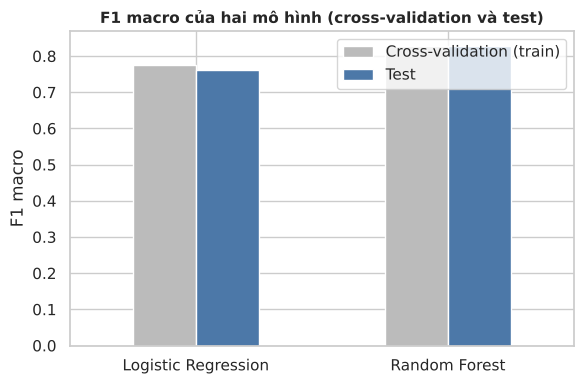

Mô hình chọn: Random Forest | AUC: {'Healthy': 0.969, 'Less Healthy': 0.979, 'Moderate': 0.902}
main_category     n  accuracy  f1_macro
    beverages 283.0     0.894     0.797
      dairies 443.0     0.916     0.891
        meals 433.0     0.755     0.609
       snacks 441.0     0.798     0.699


In [2]:
tab = cv_res.merge(test_res, on="mo_hinh").set_index("mo_hinh")
print(tab[["CV_accuracy", "CV_f1_macro", "Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "ROC_AUC_macro_ovr"]].round(3))

fig, ax = plt.subplots(figsize=(6, 4))
piv = tab[["CV_f1_macro", "F1_macro"]].rename(columns={"CV_f1_macro": "Cross-validation (train)", "F1_macro": "Test"})
piv.plot(kind="bar", ax=ax, color=["#bbbbbb", "#4c78a8"], edgecolor="white")
ax.set_title("F1 macro của hai mô hình (cross-validation và test)", fontsize=11, fontweight="bold")
ax.set_ylabel("F1 macro")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("final_model_comparison.png", dpi=120)
plt.show()
print("Mô hình chọn:", best["best_model"], "| AUC:", {k: round(v, 3) for k, v in best["auc"].items()})
print(pd.read_csv("performance_by_category.csv").round(3).to_string(index=False))

**Kết quả chính:** **Random Forest** trên bộ đặc trưng đã chọn (không chứa 4 chất tạo nhãn) đạt **accuracy 83,6%, precision macro 0,824, recall macro 0,831, F1 macro 0,827** trên tập test, ROC-AUC macro 0,950 (từ 0,902 ở Moderate đến 0,979 ở Less Healthy). Logistic Regression thấp hơn ở mọi chỉ số (accuracy 78,4%, F1 macro 0,761; Weighted F1 0,780 so với 0,838 của Random Forest). Điểm cross-validation (F1 macro 0,827) trùng điểm test nên mô hình ổn định. Bộ đặc trưng cố ý loại 4 chất tạo nhãn để mô hình không chỉ học lại công thức tính nhãn.

**So sánh với phân cụm K-Means (notebook 06, mục 7):** K-Means không giám sát cho ARI = 0,431 và NMI = 0,398 so với nhãn FSA. Hai đầu khớp rõ (cụm năng lượng thấp: 87,2% Healthy; cụm năng lượng, đường cao: 77,3% Less Healthy), còn Moderate bị chia vào cả ba cụm. Nhãn Moderate cũng là nhãn cả hai mô hình dự đoán kém nhất (F1 0,717 với Random Forest, 0,577 với Logistic Regression).

## 3. Trả lời các câu hỏi nghiên cứu

### RQ1 – Phân bố dinh dưỡng giữa các danh mục

In [3]:
cols = ["energy-kcal_100g", "fat_100g", "sugars_100g", "salt_100g", "proteins_100g"]
print(data.groupby("main_category")[cols].median().round(2))
print()
print((pd.crosstab(data["main_category"], data["health_label"], normalize="index")[LABELS] * 100).round(1))

               energy-kcal_100g  fat_100g  sugars_100g  salt_100g  proteins_100g
main_category                                                                   
beverages                  39.0      0.01          4.1       0.02           0.22
dairies                   128.0      7.90          3.8       0.15           5.60
meals                     134.0      4.40          2.2       0.80           5.60
snacks                    473.0     22.00         23.0       0.51           7.00

health_label   Healthy  Moderate  Less Healthy
main_category                                 
beverages         80.5      14.4           5.2
dairies           41.1      19.4          39.5
meals             56.1      40.1           3.8
snacks             7.7      27.7          64.7


**Trả lời:** có sự khác biệt rất lớn và có ý nghĩa thống kê (Kruskal–Wallis, p < 0,001 cho mọi chỉ số, ở notebook 03 (EDA)). Snacks có năng lượng trung vị 473 kcal và 64,7% thuộc Less Healthy; dairies nhiều béo bão hòa (39,5% Less Healthy); meals muối cao nhất nhưng chỉ 3,8% Less Healthy; beverages 80,5% Healthy nhưng đường lỏng là điểm yếu.

### RQ2 – Tương quan đường, béo bão hòa, năng lượng

**Trả lời:** năng lượng tương quan mạnh với béo bão hòa (Spearman 0,77) và béo (0,88), yếu hơn với đường (0,29). Béo và béo bão hòa gần như trùng nhau (0,91), còn đường gần độc lập với béo (0,12): đường và béo là hai con đường riêng làm sản phẩm kém lành mạnh. Chiều tương quan đường–năng lượng đổi dấu theo danh mục (beverages +0,68, dairies −0,56), nên cần phân tích theo từng nhóm.

### RQ3 – Nutri-Score tốt giữa các quốc gia

In [4]:
s = data.dropna(subset=["country_single"])
print("Số sản phẩm bán ở đúng 1 nước:", len(s))
print((pd.crosstab(s["country_single"], s["health_label"], normalize="index")[LABELS] * 100).round(1))
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(s["country_single"], s["health_label"]))
print(f"\nChi-square nhãn FSA theo nước: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2g}")

Số sản phẩm bán ở đúng 1 nước: 4685
health_label    Healthy  Moderate  Less Healthy
country_single                                 
belgium            46.6      29.6          23.8
france             44.7      25.6          29.7
germany            41.8      27.4          30.8
spain              47.9      31.1          21.0
united-kingdom     50.7      30.3          18.9

Chi-square nhãn FSA theo nước: chi2 = 58.1, dof = 8, p = 1.1e-09


**Trả lời:** tỷ lệ Nutri-Score A/B (EDA) cao nhất ở Anh (33,1%) và Pháp (31,2%), thấp nhất ở Đức và Bỉ (≈24,5%). Dùng nhãn FSA của nhóm, Anh vẫn đứng đầu (50,7% Healthy) nhưng Tây Ban Nha và Bỉ lại cao hơn Pháp và Đức. Vì thứ tự giữa các nước **không ổn định giữa hai cách chấm**, và chênh lệch chỉ khoảng 9 điểm phần trăm giữa nước cao nhất và thấp nhất, kết luận an toàn là: khác biệt có ý nghĩa thống kê (p rất nhỏ do mẫu lớn) nhưng nhỏ, và chịu ảnh hưởng của cơ cấu danh mục từng nước; chưa đủ cơ sở nói nước nào "lành mạnh hơn".

### RQ4 – Yếu tố quan trọng nhất

In [5]:
print(pd.read_csv("feature_importance.csv").round(4).to_string(index=False))

           dac_trung  giam_F1    std
    energy-kcal_100g   0.4538 0.0108
       main_category   0.1161 0.0066
          fiber_100g   0.0353 0.0034
protein_energy_share   0.0296 0.0050
       proteins_100g   0.0239 0.0041
         additives_n   0.0205 0.0039
           has_fiber   0.0025 0.0015


**Trả lời:** **mật độ năng lượng** là yếu tố quan trọng nhất (xáo trộn làm F1 giảm 0,45, gần 4 lần biến kế tiếp), sau đó là **danh mục sản phẩm** (0,116), chất xơ (0,035), % năng lượng từ đạm (0,030), đạm (0,024), phụ gia (0,021). Ở EDA, điểm Nutri-Score cũng liên quan mạnh nhất với năng lượng (0,71), béo bão hòa (0,68), béo (0,67).

### RQ5 – Dự đoán cho sản phẩm thiếu nhãn

**Trả lời:** **có, ở mức khá tốt.** Trên tập test (1.600 sản phẩm không tham gia huấn luyện), mô hình dự đoán nhãn FSA đúng 83,6% (F1 macro 0,827) mà không dùng 4 chất tạo nhãn. Less Healthy và Healthy được nhận ra tốt (F1 0,882 và 0,881), Moderate yếu hơn (0,717) và lỗi chủ yếu xảy ra giữa hai lớp kề nhau (chỉ 13/687 Healthy bị đoán thành Less Healthy). Mô hình khớp Nutri-Score gộp 65,4%, tương đương mức khớp giữa nhãn FSA và Nutri-Score (67,3%), nên không nên xem là thay thế Nutri-Score.

### RQ6 – NOVA và phụ gia

In [6]:
k = data.dropna(subset=["nova_group"])
print((pd.crosstab(k["nova_group"], k["health_label"], normalize="index")[LABELS] * 100).round(1))
print()
print(k.groupby("nova_group")["additives_n"].agg(["count", "mean", "median"]).round(2))

health_label  Healthy  Moderate  Less Healthy
nova_group                                   
1.0              79.0      14.6           6.4
2.0               0.8       0.0          99.2
3.0              38.8      26.2          35.0
4.0              38.9      28.8          32.3

            count  mean  median
nova_group                     
1.0           603  0.04     0.0
2.0           113  0.00     0.0
3.0          1925  0.25     0.0
4.0          4522  2.54     2.0


**Trả lời:** phụ gia tăng rõ theo mức chế biến: trung bình 0,04 (NOVA 1), 0 (NOVA 2), 0,25 (NOVA 3) và 2,54 (NOVA 4); Spearman 0,65, Kruskal–Wallis p ≈ 0 (EDA). Tuy nhiên mối liên hệ này một phần mang tính định nghĩa vì phụ gia là dấu hiệu để xếp NOVA 4. Điều thú vị: NOVA 1 có 79,0% Healthy theo FSA, nhưng NOVA 3 (38,8%) và NOVA 4 (38,9%) gần như **không khác nhau** về tỷ lệ Healthy. Tức là mức độ chế biến cao không đồng nghĩa với nhiều béo, đường, muối hơn, và hai thước đo (NOVA và nhãn dinh dưỡng) bổ sung cho nhau. NOVA 2 (chỉ 113 sản phẩm, như dầu, đường, bơ) gần như toàn Less Healthy (99,2%) nên cần thận trọng khi diễn giải.

### RQ7 – Khuyến nghị

In [7]:
cols = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "sugars_100g", "salt_100g"]
ref = pd.read_csv("cleaned_dataset.csv", dtype={"code": str})[["code", "saturated-fat_100g"]]
tmp = data.drop(columns=[c for c in ["saturated-fat_100g"] if c in data.columns]).merge(ref, on="code", how="left")
print("Trung vị mỗi chỉ số theo nhãn (trên 100g):")
print(tmp.groupby("health_label")[cols].median().reindex(LABELS).round(2).T)

Trung vị mỗi chỉ số theo nhãn (trên 100g):
health_label        Healthy  Moderate  Less Healthy
energy-kcal_100g      57.00    213.01        464.00
fat_100g               1.40      8.00         25.00
saturated-fat_100g     0.30      2.50         14.00
sugars_100g            3.30      3.60         12.00
salt_100g              0.13      0.74          0.65


**Trả lời:** xem mục 5 bên dưới.

## 4. Năm insight định lượng
1. **Snacks là nhóm rủi ro nhất:** 64,7% thuộc Less Healthy (so với 3,8% ở meals và 5,2% ở beverages); năng lượng trung vị 473 kcal/100g; 78,2% là siêu chế biến; 49,2% Nutri-Score E.
2. **Dairies bị đánh giá thấp chủ yếu vì béo bão hòa:** 39,5% thuộc Less Healthy, và trong nhóm này 99% vượt ngưỡng béo bão hòa nhưng chỉ 2% vượt ngưỡng đường.
3. **Snacks kém vì cả béo lẫn đường:** trong số snacks Less Healthy, 87% vượt ngưỡng béo, 79% béo bão hòa, 69% đường; chỉ 11% vượt ngưỡng muối.
4. **Meals cần chú ý muối:** meals có muối trung vị cao nhất (0,8 g/100g), và trong nhóm meals Less Healthy (chỉ 83 sản phẩm), 72% vượt ngưỡng muối.
5. **Mật độ năng lượng là tín hiệu mạnh nhất:** sản phẩm Healthy có năng lượng trung vị 57 kcal/100g, Moderate 213, Less Healthy 464 kcal/100g; chỉ cần năng lượng, đạm, chất xơ, phụ gia và danh mục đã dự đoán đúng 83,6% nhãn.

## 5. Khuyến nghị
**Cho người tiêu dùng**
- Xem nhanh **năng lượng trên 100g**: dưới khoảng 60 kcal thường thuộc nhóm Healthy, còn nhóm Less Healthy có trung vị 464 kcal (trung vị Healthy là 57 kcal).
- **Snacks:** ưu tiên sản phẩm dưới 22,5 g đường, dưới 17,5 g béo và dưới 5 g béo bão hòa trên 100g (ngưỡng "cao" của FSA). Khoảng một nửa số snacks vượt từng ngưỡng đường (50,8%) hoặc béo bão hòa (53,0%).
- **Sữa và chế phẩm:** chọn loại ít béo bão hòa (dưới 5 g/100g); đường không phải vấn đề chính ở nhóm này.
- **Món ăn chế biến sẵn, súp, nước sốt:** đọc nhãn muối, giữ dưới 1,5 g/100g (đồ uống dưới 0,75 g/100ml).
- **Đồ uống:** chọn loại dưới 2,5 g đường/100ml (ngưỡng thấp); vẫn có 9,4% đồ uống vượt ngưỡng đường cao.
- Đừng chỉ dùng mức độ chế biến (NOVA) để đánh giá: NOVA 3 và 4 có tỷ lệ Healthy gần như bằng nhau; nên kết hợp với nhãn dinh dưỡng.

**Cho doanh nghiệp**
- Snacks: giảm đồng thời béo bão hòa và đường, vì đa số sản phẩm Less Healthy vượt cả hai ngưỡng.
- Dairies: giảm béo bão hòa (đổi công thức, sản phẩm ít béo) là đòn bẩy lớn nhất.
- Meals: giảm muối.
- Công bố đầy đủ chất xơ và Nutri-Score: 30,6% sản phẩm thiếu chất xơ và 4,9% thiếu Nutri-Score, làm giảm khả năng so sánh trên thị trường.

## 6. Hạn chế và hướng phát triển
- **Nhãn là nhãn tự xây:** dựa trên 4 chất theo ngưỡng FSA, không tính đạm, chất xơ, rau quả như Nutri-Score; mô hình dự đoán nhãn này chứ không phải "độ lành mạnh" tuyệt đối. Quy tắc gán nhãn (Healthy: không ô đỏ và tổng điểm ≤ 2; Less Healthy: từ 2 ô đỏ trở lên hoặc tổng điểm ≥ 5; còn lại là Moderate) là lựa chọn của nhóm.
- **Rò rỉ gián tiếp:** năng lượng được tính từ béo, đường, đạm nên bộ đặc trưng vẫn mang thông tin gián tiếp về nhãn. Kết quả 83,6% nên hiểu là "dự đoán chất lượng từ năng lượng, đạm, chất xơ, phụ gia, danh mục", không phải dự đoán từ tên hay hình ảnh sản phẩm.
- **Dữ liệu cộng đồng:** thiên lệch theo nước, hãng và độ phủ nhập liệu; hạng và điểm Nutri-Score đôi khi không khớp (lẫn cách tính cũ và mới); 41% sản phẩm bán ở nhiều nước nên so sánh quốc gia chỉ dùng được nhóm bán ở một nước.
- **Mô hình:** chưa tinh chỉnh siêu tham số kỹ; lớp Moderate còn yếu (F1 0,717, và là lớp K-Means cũng khớp kém nhất với nhãn); meals (F1 0,609) và snacks (0,699) thấp hơn dairies (0,891).
- **Hướng phát triển:** thử Gradient Boosting và tinh chỉnh siêu tham số; thêm thành phần (danh sách nguyên liệu) vào đặc trưng; kiểm chứng ngoài mẫu bằng dữ liệu nước khác; chia train/test theo thương hiệu để kiểm tra khả năng tổng quát hóa; thử quy tắc nhãn khác (ví dụ chỉ dùng tổng điểm FSA với ngưỡng 2 và 4 điểm) và so sánh lại bằng ARI/NMI với K-Means.